# Milestone 1 – Video Game Sales Analysis

**Dataset:** Video Game Sales (Kaggle) – `vgsales.csv`

In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [46]:
df=pd.read_csv("vgsales.csv")
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [47]:
df.shape

(16598, 11)

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 2.1 MB


In [49]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [50]:
df.columns

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='str')

In [51]:
df.dtypes

Rank              int64
Name                str
Platform            str
Year            float64
Genre               str
Publisher           str
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

In [52]:
df["Genre"].unique()

<ArrowStringArray>
[      'Sports',     'Platform',       'Racing', 'Role-Playing',
       'Puzzle',         'Misc',      'Shooter',   'Simulation',
       'Action',     'Fighting',    'Adventure',     'Strategy']
Length: 12, dtype: str

In [53]:
df["Platform"].unique()

<ArrowStringArray>
[ 'Wii',  'NES',   'GB',   'DS', 'X360',  'PS3',  'PS2', 'SNES',  'GBA',
  '3DS',  'PS4',  'N64',   'PS',   'XB',   'PC', '2600',  'PSP', 'XOne',
   'GC', 'WiiU',  'GEN',   'DC',  'PSV',  'SAT',  'SCD',   'WS',   'NG',
 'TG16',  '3DO',   'GG', 'PCFX']
Length: 31, dtype: str

In [54]:
# Dropping the "Rank" column as it is not needed for analysis
df.drop("Rank",axis=1,inplace=True)
df.head()

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [55]:
# it will give the duplicate rows present in the dataset
df[df.duplicated()]

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
14999,Wii de Asobu: Metroid Prime,Wii,NaN,Shooter,Nintendo,0.0,0.0,0.02,0.0,0.02


In [56]:
# dropping duplicate rows
df.drop_duplicates(inplace = True)

In [57]:
df.shape

(16597, 10)

In [58]:
# missing values in dataset
df.isnull().sum()

Name              0
Platform          0
Year            270
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

<Axes: xlabel='Year', ylabel='Count'>

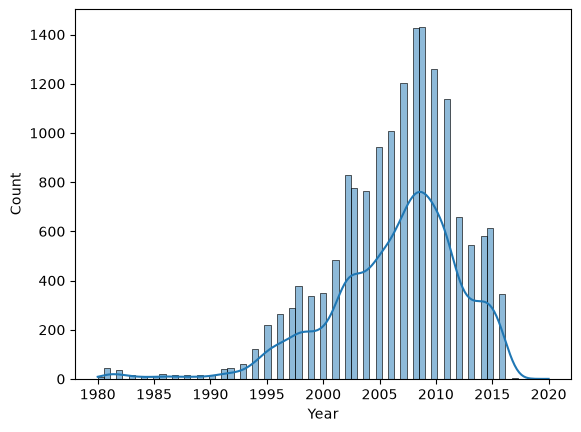

In [59]:
sns.histplot(df["Year"],kde=True)

In [60]:
# replacing null values in "Year" column 
df["Year_mean"] = df["Year"].fillna(df["Year"].mean())

In [61]:
df[df["Publisher"].isnull()]

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Year_mean
470,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,NaN,1.57,1.02,0.00,0.41,3.00,2006.406443
1303,Triple Play 99,PS,NaN,Sports,NaN,0.81,0.55,0.00,0.10,1.46,2006.406443
1662,Shrek / Shrek 2 2-in-1 Gameboy Advance Video,GBA,2007.0,Misc,NaN,0.87,0.32,0.00,0.02,1.21,2007.000000
2222,Bentley's Hackpack,GBA,2005.0,Misc,NaN,0.67,0.25,0.00,0.02,0.93,2005.000000
3159,Nicktoons Collection: Game Boy Advance Video V...,GBA,2004.0,Misc,NaN,0.46,0.17,0.00,0.01,0.64,2004.000000
3166,SpongeBob SquarePants: Game Boy Advance Video ...,GBA,2004.0,Misc,NaN,0.46,0.17,0.00,0.01,0.64,2004.000000
3766,SpongeBob SquarePants: Game Boy Advance Video ...,GBA,2004.0,Misc,NaN,0.38,0.14,0.00,0.01,0.53,2004.000000
4145,Sonic the Hedgehog,PS3,NaN,Platform,NaN,0.00,0.48,0.00,0.00,0.48,2006.406443
4526,The Fairly Odd Parents: Game Boy Advance Video...,GBA,2004.0,Misc,NaN,0.31,0.11,0.00,0.01,0.43,2004.000000
4635,The Fairly Odd Parents: Game Boy Advance Video...,GBA,2004.0,Misc,NaN,0.30,0.11,0.00,0.01,0.42,2004.000000


In [62]:
# seperating the dataset for Action genre games
df_action=df[df["Genre"]=="Action"]
df_action.shape

(3316, 11)

In [63]:
df_action.head()

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Year_mean
16,Grand Theft Auto V,PS3,2013.0,Action,Take-Two Interactive,7.01,9.27,0.97,4.14,21.40,2013.0
17,Grand Theft Auto: San Andreas,PS2,2004.0,Action,Take-Two Interactive,9.43,0.40,0.41,10.57,20.81,2004.0
23,Grand Theft Auto V,X360,2013.0,Action,Take-Two Interactive,9.63,5.31,0.06,1.38,16.38,2013.0
24,Grand Theft Auto: Vice City,PS2,2002.0,Action,Take-Two Interactive,8.41,5.49,0.47,1.78,16.15,2002.0
38,Grand Theft Auto III,PS2,2001.0,Action,Take-Two Interactive,6.99,4.51,0.30,1.30,13.10,2001.0


In [64]:
# games published by Nintendo
df_nintendo=df[df["Publisher"]=="Nintendo"]
df_nintendo.shape

(702, 11)

In [65]:
df_nintendo.head()

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Year_mean
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,2006.0
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,1985.0
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,2008.0
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,2009.0
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,1996.0


In [66]:
df["Genre"].value_counts()

Genre
Action          3316
Sports          2346
Misc            1739
Role-Playing    1488
Shooter         1309
Adventure       1286
Racing          1249
Platform         886
Simulation       867
Fighting         848
Strategy         681
Puzzle           582
Name: count, dtype: int64

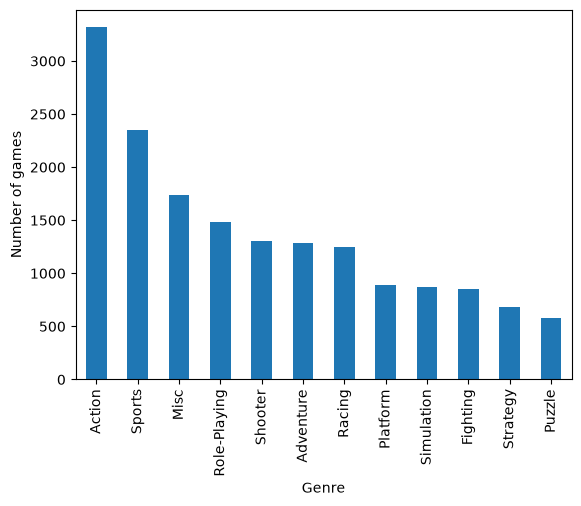

In [67]:
df["Genre"].value_counts().plot(kind="bar")
plt.xlabel("Genre")
plt.ylabel("Number of games")
plt.show()

In [68]:
# number og games on each platform
df["Platform"].value_counts()

Platform
DS      2163
PS2     2161
PS3     1329
Wii     1324
X360    1265
PSP     1213
PS      1196
PC       960
XB       824
GBA      822
GC       556
3DS      509
PSV      413
PS4      336
N64      319
SNES     239
XOne     213
SAT      173
WiiU     143
2600     133
NES       98
GB        98
DC        52
GEN       27
NG        12
SCD        6
WS         6
3DO        3
TG16       2
GG         1
PCFX       1
Name: count, dtype: int64

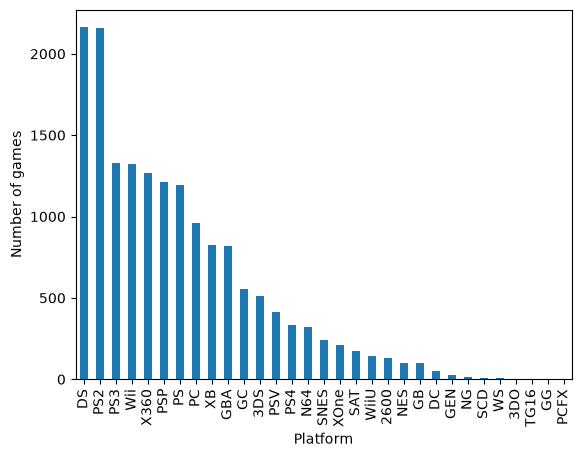

In [69]:
df["Platform"].value_counts().plot(kind ="bar")
plt.xlabel("Platform")
plt.ylabel("Number of games")
plt.show()

In [70]:
#average global sales of a game in each genre
df.groupby("Genre")["Global_Sales"].mean()

Genre
Action          0.528100
Adventure       0.185879
Fighting        0.529375
Misc            0.465762
Platform        0.938341
Puzzle          0.420876
Racing          0.586101
Role-Playing    0.623233
Shooter         0.792475
Simulation      0.452364
Sports          0.567319
Strategy        0.257151
Name: Global_Sales, dtype: float64

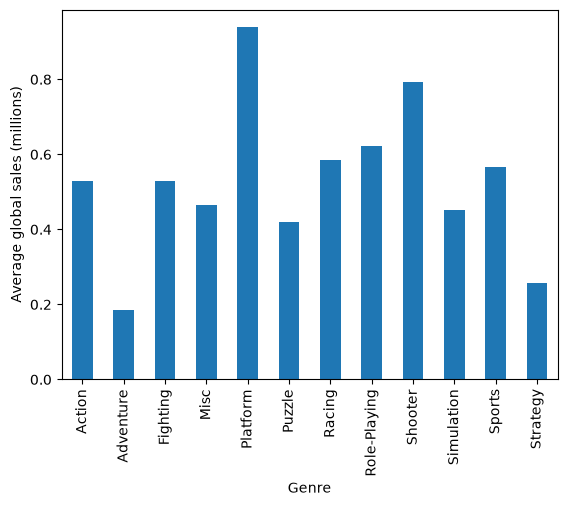

In [71]:
df.groupby("Genre")["Global_Sales"].mean().plot(kind="bar")
plt.xlabel("Genre")
plt.ylabel("Average global sales (millions)")
plt.show()

In [72]:
#average global sales of a game on each platform 
df.groupby("Platform")["Global_Sales"].mean()

Platform
2600    0.729925
3DO     0.033333
3DS     0.486169
DC      0.307115
DS      0.380254
GB      2.606633
GBA     0.387470
GC      0.358561
GEN     1.050370
GG      0.040000
N64     0.686144
NES     2.561939
NG      0.120000
PC      0.269604
PCFX    0.030000
PS      0.610920
PS2     0.581046
PS3     0.720722
PS4     0.827679
PSP     0.244254
PSV     0.149952
SAT     0.194162
SCD     0.311667
SNES    0.837029
TG16    0.080000
WS      0.236667
Wii     0.699917
WiiU    0.572448
X360    0.774672
XB      0.313422
XOne    0.662254
Name: Global_Sales, dtype: float64

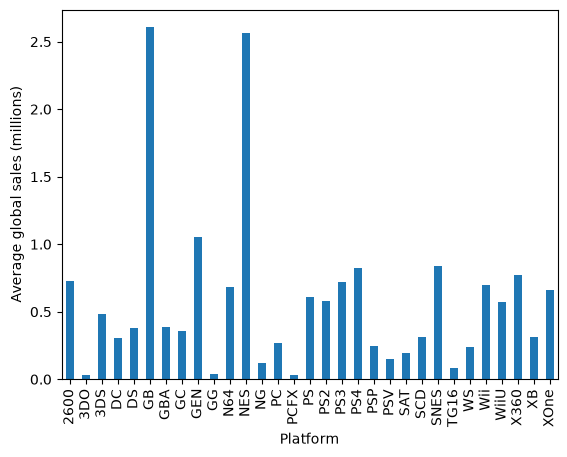

In [73]:
df.groupby("Platform")["Global_Sales"].mean().plot(kind="bar")
plt.xlabel("Platform")
plt.ylabel("Average global sales (millions)")
plt.show()

In [74]:
# region wise sales
df[["NA_Sales","EU_Sales","JP_Sales","Other_Sales"]].mean()

NA_Sales       0.264683
EU_Sales       0.146661
JP_Sales       0.077785
Other_Sales    0.048066
dtype: float64

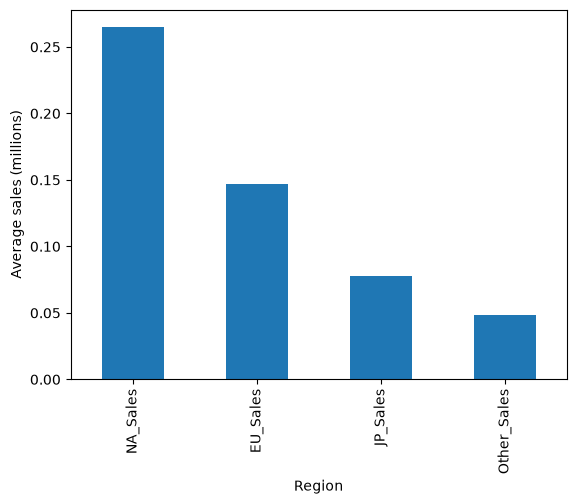

In [75]:
df[["NA_Sales","EU_Sales","JP_Sales","Other_Sales"]].mean().plot(kind="bar")
plt.xlabel("Region")
plt.ylabel("Average sales (millions)")
plt.show()

In [76]:
# average global sales of a game by release year
df.groupby("Year")["Global_Sales"].mean()

Year
1980.0    1.264444
1981.0    0.777609
1982.0    0.801667
1983.0    0.987647
1984.0    3.597143
1985.0    3.852857
1986.0    1.765238
1987.0    1.358750
1988.0    3.148000
1989.0    4.320588
1990.0    3.086875
1991.0    0.786098
1992.0    1.771163
1993.0    0.766333
1994.0    0.654298
1995.0    0.402329
1996.0    0.757224
1997.0    0.695433
1998.0    0.676702
1999.0    0.743402
2000.0    0.577536
2001.0    0.687697
2002.0    0.477105
2003.0    0.461742
2004.0    0.549554
2005.0    0.488778
2006.0    0.516905
2007.0    0.508428
2008.0    0.475420
2009.0    0.466317
2010.0    0.476926
2011.0    0.453020
2012.0    0.553333
2013.0    0.674194
2014.0    0.579124
2015.0    0.430684
2016.0    0.206192
2017.0    0.016667
2020.0    0.290000
Name: Global_Sales, dtype: float64

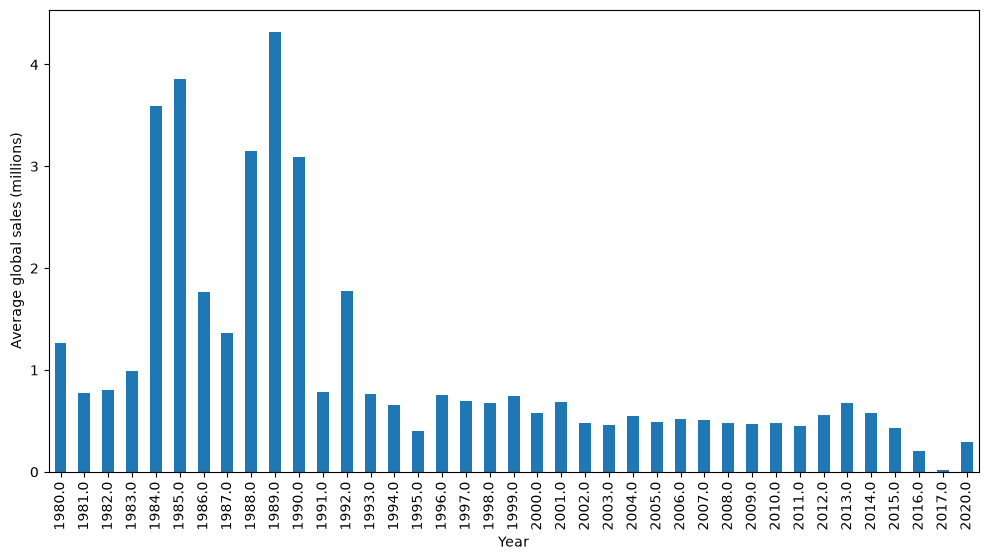

In [77]:
plt.figure(figsize=(12,6))
df.groupby("Year")["Global_Sales"].mean().plot(kind="bar")
plt.xlabel("Year")
plt.ylabel("Average global sales (millions)")
plt.show()

<Axes: xlabel='Global_Sales', ylabel='Count'>

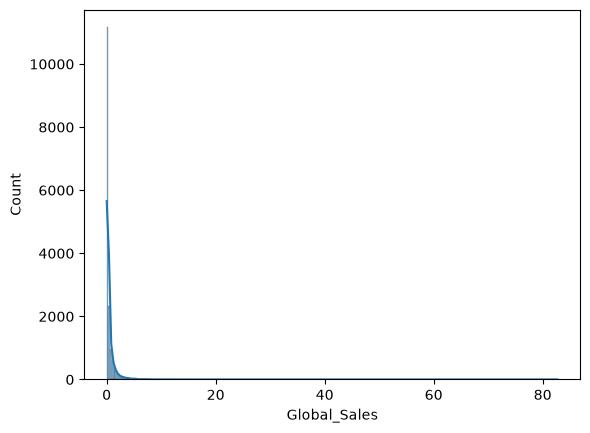

In [78]:
sns.histplot(df["Global_Sales"],kde=True)

<Axes: xlabel='NA_Sales', ylabel='EU_Sales'>

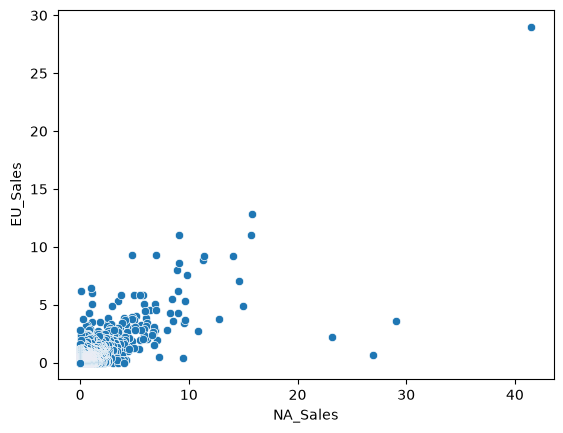

In [79]:
sns.scatterplot(x=df["NA_Sales"],y=df["EU_Sales"])

In [80]:
# correlation between the regional sales columns
df[["NA_Sales","EU_Sales","JP_Sales","Other_Sales","Global_Sales"]].corr()

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
NA_Sales,1.000000,0.767725,0.449786,0.634736,0.941047
EU_Sales,0.767725,1.000000,0.435583,0.726384,0.902835
JP_Sales,0.449786,0.435583,1.000000,0.290184,0.611814
Other_Sales,0.634736,0.726384,0.290184,1.000000,0.748330
Global_Sales,0.941047,0.902835,0.611814,0.748330,1.000000


<Axes: >

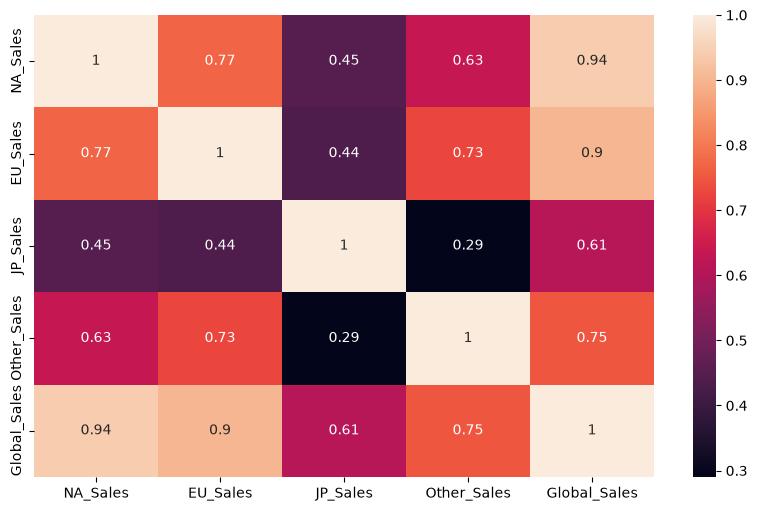

In [81]:
plt.figure(figsize=(10,6))
sns.heatmap(df[["NA_Sales","EU_Sales","JP_Sales","Other_Sales","Global_Sales"]].corr(),annot=True)

In [82]:
# different genres of Nintendo games
df_nintendo["Genre"].value_counts()

Genre
Platform        112
Role-Playing    106
Misc            100
Action           79
Puzzle           74
Sports           55
Racing           37
Adventure        35
Strategy         32
Simulation       29
Shooter          25
Fighting         18
Name: count, dtype: int64

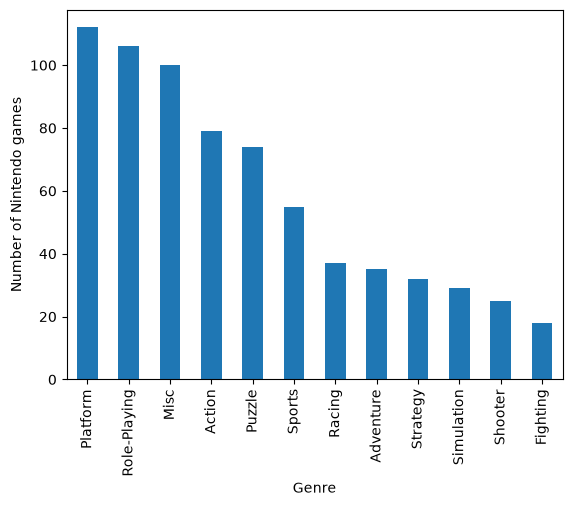

In [83]:
df_nintendo["Genre"].value_counts().plot(kind="bar")
plt.xlabel("Genre")
plt.ylabel("Number of Nintendo games")
plt.show()